# What Is a Neural Network, Really? Building a Neuron in Python

*The First Epoch · Neurons to Networks · Part 1*

Here is a small puzzle to begin with. Below are six temperatures measured in Celsius, together with the same temperatures expressed in Fahrenheit. A simple formula converts one scale into the other, but suppose for a moment that you had never seen it. Could you recover that formula from the data alone?

| Celsius | −10 | 0 | 10 | 20 | 30 | 40 |
|:--|:--:|:--:|:--:|:--:|:--:|:--:|
| **Fahrenheit** | 14 | 32 | 50 | 68 | 86 | 104 |

In this notebook we will answer that question with the smallest building block of every neural network: a single artificial neuron. We will write it from scratch in plain Python, without any machine learning library, and by the end it will have rediscovered the conversion formula for us. Along the way you will see that, beneath all the excitement surrounding artificial intelligence, a neuron does something remarkably simple.

## 1. What is an artificial neuron?

Neural networks were loosely inspired by the brain. A biological neuron receives signals from many other neurons, some of which matter more than others, and when the combined signal is strong enough, the neuron fires and passes a signal of its own onward.

An artificial neuron keeps only this central idea and leaves the biology behind. It performs three steps, one after another:

1. **It multiplies.** The neuron receives a list of numbers, called its *inputs*, and multiplies each one by a *weight*. A weight expresses how much that particular input matters; a large weight means the input has a strong influence, and a negative weight means the input pushes the result down.
2. **It adds.** The neuron adds all of these weighted inputs together, and then adds one more number, called the *bias*, which shifts the total up or down regardless of the inputs.
3. **It decides.** Finally, the neuron passes the total through an *activation function*, which turns it into the neuron's output.

Written as an equation, a neuron with inputs $x_1, x_2, \dots, x_n$, weights $w_1, w_2, \dots, w_n$ and bias $b$ first computes

$$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b = \sum_{i=1}^{n} w_i x_i + b,$$

and then produces its output by applying an activation function $f$, so that the output is $f(z)$. Multiply, add, decide: that is the whole of it.

## 2. An everyday example: should I go for a run?

To make this concrete, imagine that you are deciding whether to go for a run this evening. Three questions influence your decision, and each answer becomes an input to the neuron, with 1 meaning *yes* and 0 meaning *no*:

| Question | Input | Weight |
|:--|:--:|:--:|
| Is it sunny? | 1 | +2 |
| Is the temperature comfortable? | 1 | +3 |
| Am I tired? | 0 | −4 |

The weights reflect how much each factor matters to you. Comfortable weather matters a great deal, so it receives a weight of 3, while sunshine helps a little and receives a weight of 2. Tiredness is a strong reason *not* to go, so it receives a negative weight of −4. The bias, which we set to −3, captures your general reluctance: it is the amount of convincing you need before you will put your shoes on at all.

The neuron multiplies and adds:

$$z = (1 \times 2) + (1 \times 3) + (0 \times -4) + (-3) = 2.$$

For the decision step we use the simplest activation function there is, the *step function*, which outputs 1 when the total is positive and 0 otherwise. Since the total is 2, the neuron outputs 1, and you go for your run. If you were tired, however, the total would fall to −2 and the neuron would tell you to stay at home. Notice that the inputs describe the situation, but it is the weights and the bias that determine how the neuron *responds* to it. This observation will turn out to be the key to learning.

## 3. Writing the neuron in Python

Let us now translate these three steps into code. The function below performs the *multiply* and *add* steps: it walks through the inputs and weights in pairs, multiplies each pair, accumulates the results, and finally adds the bias.

In [1]:
def neuron(inputs, weights, bias):
    """Return the weighted sum of the inputs plus the bias."""
    total = 0
    for x, w in zip(inputs, weights):
        total += x * w          # Multiply each input by its weight and add it up.
    return total + bias         # Finally, add the bias.

The *decide* step is a separate function, so that we can later swap in other activation functions without touching the neuron itself.

In [2]:
def step(z):
    """Output 1 if the total is positive, and 0 otherwise."""
    return 1 if z > 0 else 0

We can now ask our neuron whether to go for a run, first on a day when we are not tired and then on a day when we are.

In [3]:
weights = [2, 3, -4]   # sunny, comfortable, tired
bias = -3              # how much convincing we need before we go

print(step(neuron([1, 1, 0], weights, bias)))   # Not tired: the neuron says 1, so we go.
print(step(neuron([1, 1, 1], weights, bias)))   # Tired: the neuron says 0, so we stay home.

1
0


The neuron gives exactly the answers we worked out by hand. In fewer than ten lines of plain Python, we have built a working artificial neuron. Every neural network you have heard of, whether it recognises faces, translates languages or powers a chatbot, is assembled from enormous numbers of units much like this one.

## 4. From decisions to predictions

A neuron need not make yes-or-no decisions. If we leave out the activation function and simply use the total $z$ as the output, the neuron can produce any number at all, which means it can *predict* quantities rather than merely choose between options.

With a single input $x$, a neuron without an activation function computes

$$\text{output} = w x + b.$$

This is nothing other than the equation of a straight line, the familiar $y = mx + c$ from school mathematics. The weight $w$ plays the role of the slope, and the bias $b$ is the point where the line crosses the vertical axis. We will return to activation functions properly in Part 3 of this series; for now, a neuron without one is exactly what we need to tackle our opening puzzle.

## 5. The data

Here are our six examples once more. The neuron is not told the conversion formula; all it has are these pairs of numbers.

In [4]:
celsius    = [-10, 0, 10, 20, 30, 40]
fahrenheit = [ 14, 32, 50, 68, 86, 104]

Before we can improve the neuron, we need a way to measure how wrong it is. For now we will keep this as simple as possible: for each example, we compute the distance between the neuron's prediction and the true value, and then we take the average of those distances. In the next video we will replace this with a more principled *loss function*, but the idea will remain the same.

In [5]:
def average_error(w, b):
    """Return the average distance between the neuron's predictions and the true values."""
    errors = [abs(neuron([c], [w], b) - f)
              for c, f in zip(celsius, fahrenheit)]
    return sum(errors) / len(errors)

Finally, a small helper function will draw the true data as points and the neuron's predictions as a red line, so that we can *see* how good each guess is.

In [6]:
import matplotlib.pyplot as plt

plt.rcParams["font.size"] = 14          # Large text, so the plots are readable on a phone.
plt.rcParams["figure.figsize"] = (8, 5)

def show(w, b):
    """Plot the true data together with the neuron's straight line."""
    preds = [neuron([c], [w], b) for c in celsius]
    plt.scatter(celsius, fahrenheit, s=80, label="true data")
    plt.plot(celsius, preds, color="red", linewidth=2.5, label=f"neuron: w={w}, b={b}")
    plt.xlabel("Celsius")
    plt.ylabel("Fahrenheit")
    plt.legend()
    plt.title(f"Average error = {average_error(w, b):.1f}")
    plt.grid(alpha=0.3)
    plt.show()

## 6. Tuning the neuron by hand

Let us begin with a deliberately lazy guess, setting the weight to 1 and the bias to 0.

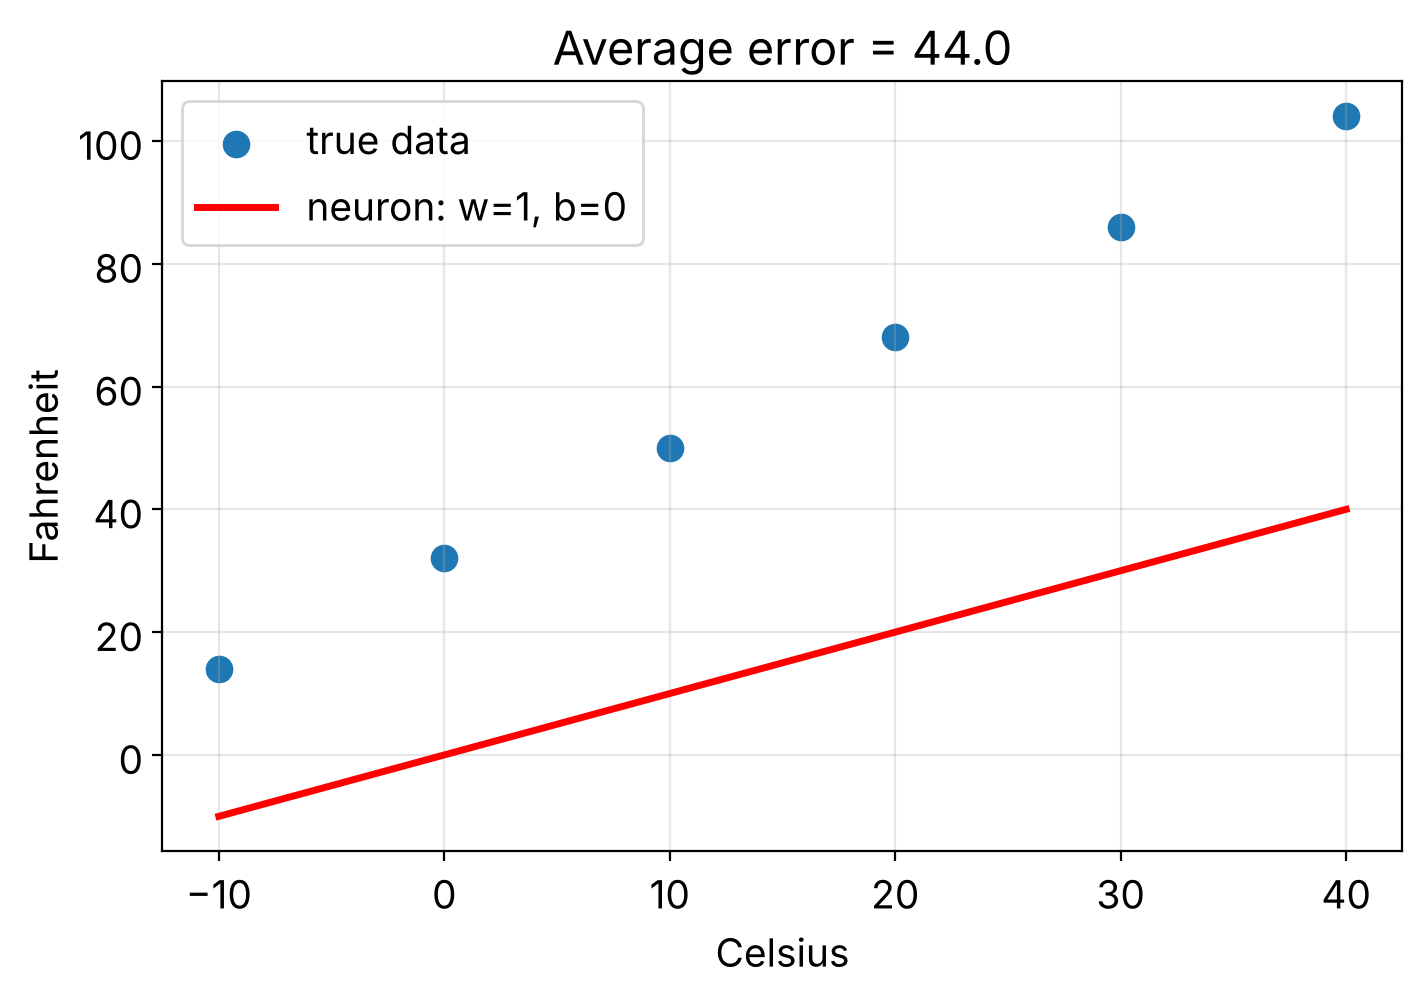

In [7]:
show(1, 0)

The line is far too flat and sits far too low, and the average error is a disappointing 44 degrees. Because the line is too flat, the natural first fix is to make it steeper, so let us increase the weight to 2.

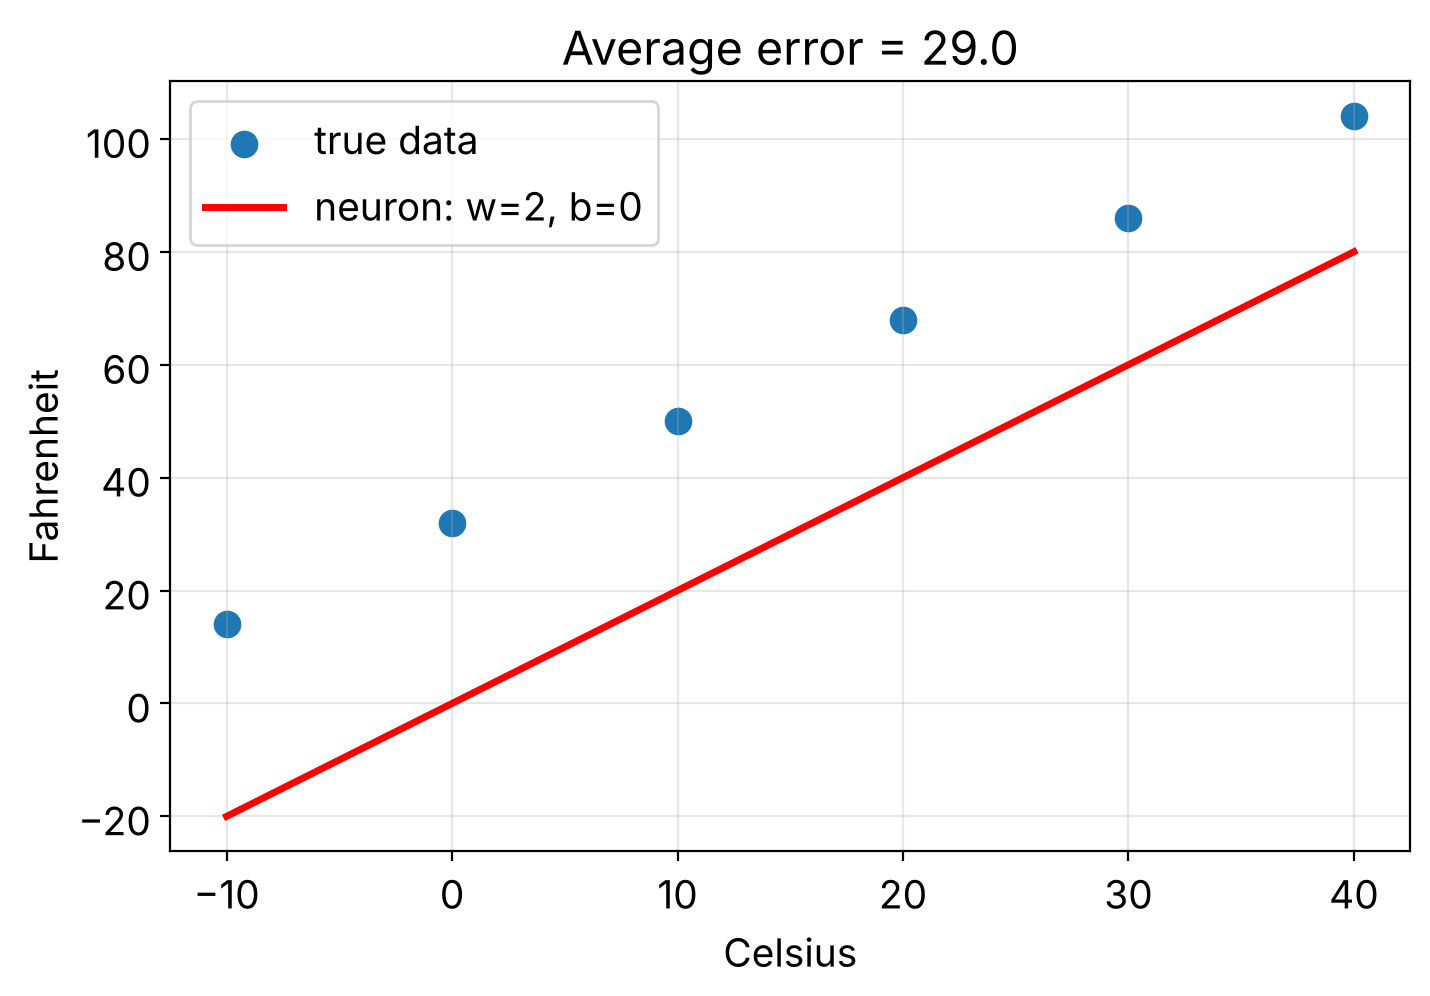

In [8]:
show(2, 0)

The average error has fallen to 29. The slope now looks roughly right, but the entire line is still too low. Shifting a line up or down is precisely the job of the bias, so let us raise it to 30.

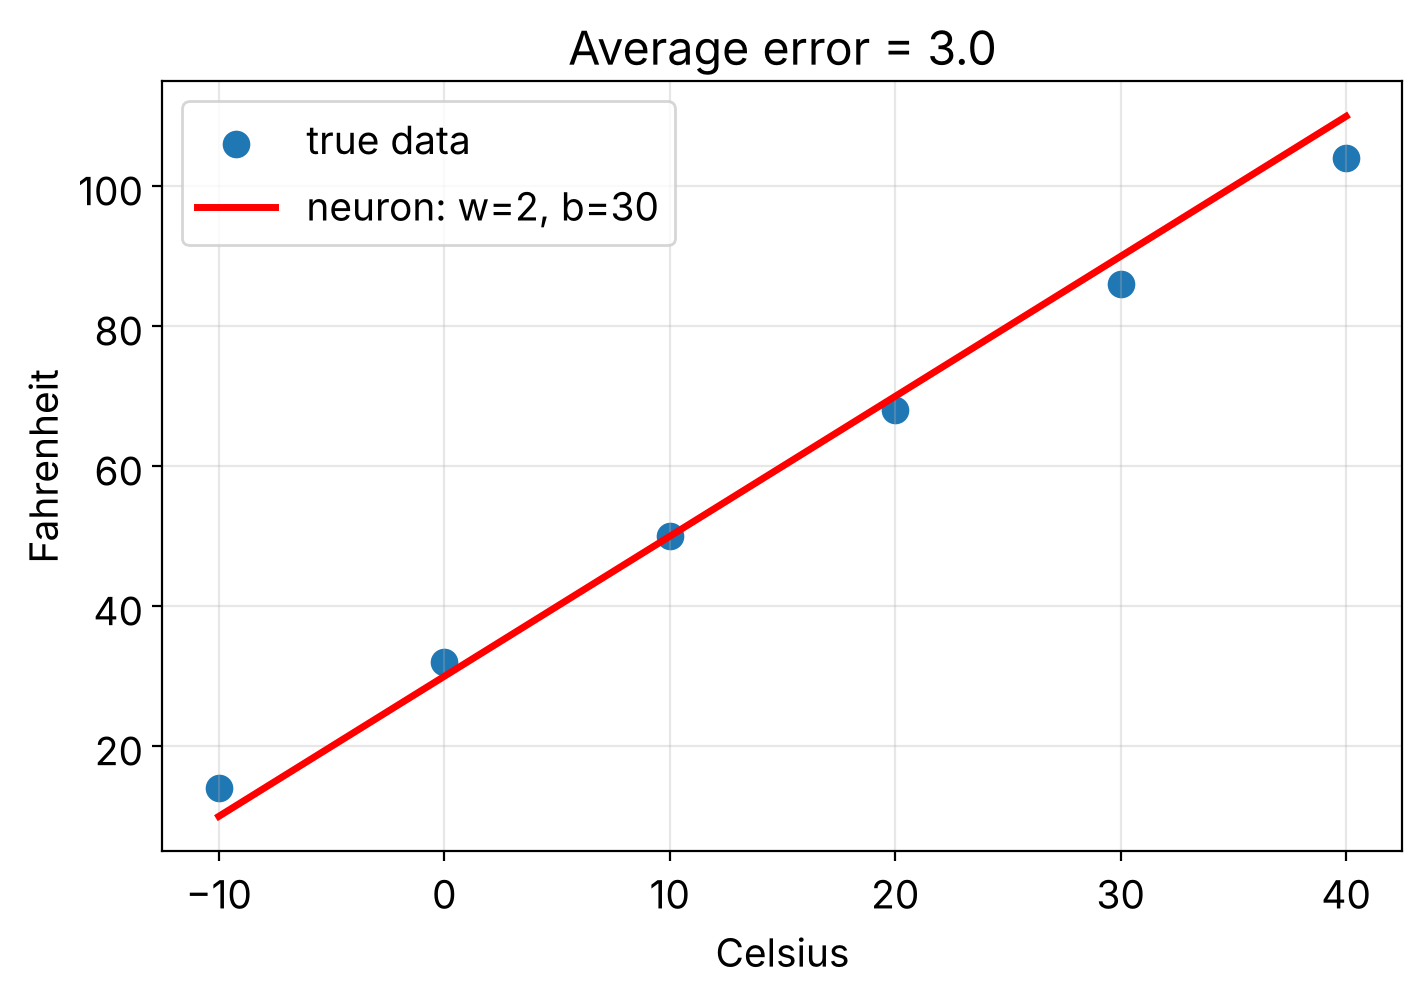

In [9]:
show(2, 30)

We are now very close, with an average error of only 3 degrees. Looking carefully, the line appears slightly too steep, so let us reduce the weight a little and nudge the bias upward to compensate.

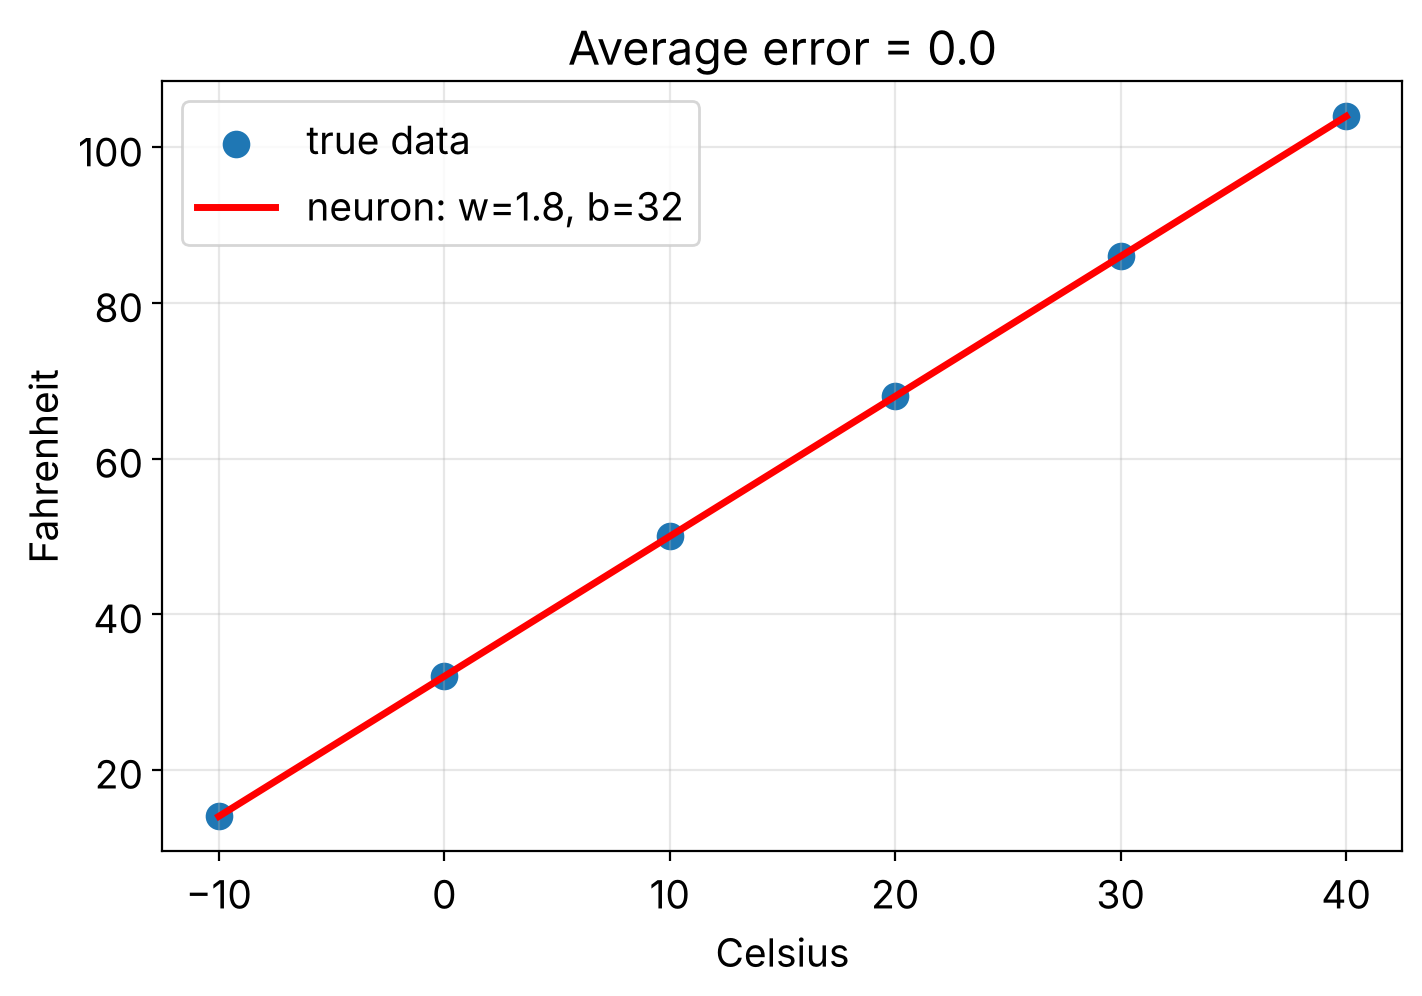

In [10]:
show(1.8, 32)

The red line now passes through every single point, and the average error is zero. Our neuron has settled on a weight of 1.8 and a bias of 32, which means it computes

$$F = 1.8 \times C + 32.$$

This is exactly the real formula for converting Celsius to Fahrenheit. We never told the neuron this formula; we recovered it purely from data, using one artificial neuron and a little patience.

| Attempt | Weight $w$ | Bias $b$ | Average error |
|:--:|:--:|:--:|:--:|
| 1 | 1 | 0 | 44.0 |
| 2 | 2 | 0 | 29.0 |
| 3 | 2 | 30 | 3.0 |
| 4 | 1.8 | 32 | 0.0 |

## 7. The problem with tuning by hand

We should be honest about what just happened. It was *we*, not the neuron, who found those numbers: we looked at each plot, made a guess, and adjusted. This worked only because there were just two numbers to tune.

Real neural networks contain thousands, millions, and sometimes billions of weights, and nobody could ever adjust them by hand. The genuinely interesting question, therefore, is how a network can adjust its *own* weights, becoming a little less wrong with every step it takes. The answer is an algorithm called **gradient descent**, which is the engine behind nearly all of modern artificial intelligence, and it is the subject of Part 2.

## 8. Summary

In this notebook we have seen that an artificial neuron multiplies its inputs by weights, adds them together with a bias, and passes the result through an activation function. The weights and the bias, rather than the inputs, determine how the neuron behaves. Without an activation function, a neuron with a single input is simply a straight line, $y = wx + b$, and by choosing its weight and bias carefully we were able to recover the Celsius-to-Fahrenheit formula from six examples. Above all, we have seen that *learning* means finding good values for the weights, which is precisely what we will teach the neuron to do for itself in the next part.

## 9. Try it yourself

The best way to make these ideas your own is to experiment with them. Here are three small challenges, in increasing order of difficulty.

1. **Change your mind about running.** Adjust the weights and the bias of the running neuron so that you go for a run whenever it is sunny, even when you are tired. Then check that you still stay at home when it is neither sunny nor comfortable.
2. **Find another formula.** The table below converts kilometres to miles. Use the `show` function, after replacing the data, to find the weight and bias by hand. What do you notice about the bias this time?

   | Kilometres | 0 | 5 | 10 | 21.1 | 42.2 |
   |:--|:--:|:--:|:--:|:--:|:--:|
   | **Miles** | 0 | 3.11 | 6.21 | 13.11 | 26.22 |

3. **Count the effort.** Try to reach an average error below 0.5 on the temperature data, starting from a different first guess. How many attempts did you need, and how would you feel about doing the same for a million weights?

If you get stuck, or if you discover something interesting, please share it in the comments under the video.

---

*Next in the series: Part 2, Gradient Descent, in which our neuron learns to find these numbers by itself.*